<a href="https://colab.research.google.com/github/souvikdey214-code/Krutanic_Weekly-Project-Task/blob/main/10_ChestScan_AI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os, copy, random
import numpy as np
import matplotlib.pyplot as plt
import cv2
from PIL import Image

import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import datasets, transforms, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, confusion_matrix, roc_curve

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
use_amp = device == "cuda"
print("Device:", device)

Device: cuda


Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Train folder  -> NORMAL: 1341  PNEUMONIA: 3875  (imbalance 2.9:1)
Test folder   -> 624 images


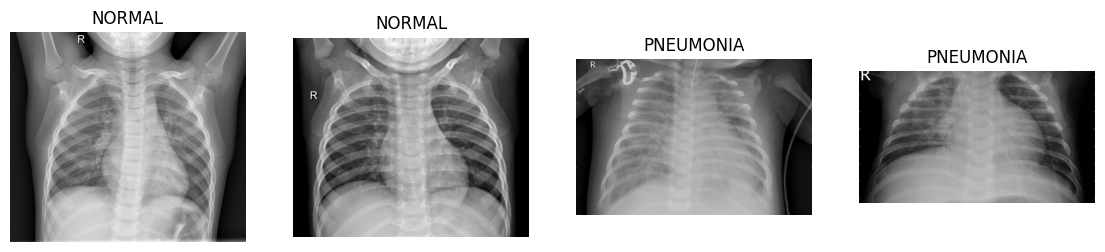

In [2]:
import kagglehub
path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")

def find_root(p):
    for dp, dn, _ in os.walk(p):
        if {"train", "test"} <= set(dn):
            return dp
    raise FileNotFoundError("train/test folders not found")

root = find_root(path)
full      = datasets.ImageFolder(os.path.join(root, "train"))
test_base = datasets.ImageFolder(os.path.join(root, "test"))
assert full.class_to_idx == {"NORMAL": 0, "PNEUMONIA": 1}, full.class_to_idx

counts = np.bincount(full.targets)
print(f"Train folder  -> NORMAL: {counts[0]}  PNEUMONIA: {counts[1]}  (imbalance {counts[1]/counts[0]:.1f}:1)")
print(f"Test folder   -> {len(test_base)} images")

fig, ax = plt.subplots(1, 4, figsize=(14, 4))
for a, (lbl, idx) in zip(ax, [(0, 0), (0, 1), (1, 0), (1, 1)]):
    sel = [i for i, t in enumerate(full.targets) if t == lbl][idx * 7]
    a.imshow(Image.open(full.samples[sel][0]).convert("L"), cmap="gray")
    a.set_title(full.classes[lbl]); a.axis("off")
plt.show()

In [3]:
norm = transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
eval_tf = transforms.Compose([transforms.Resize((224, 224)), transforms.ToTensor(), norm])
aug_light = transforms.Compose([
    transforms.Resize((224, 224)), transforms.RandomRotation(5),
    transforms.ToTensor(), norm])
aug_heavy = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.7, 1.0)), transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.3, contrast=0.3),
    transforms.ToTensor(), norm])

class XrayDS(Dataset):
    def __init__(self, base, indices, train=False):
        self.base, self.indices, self.train = base, list(indices), train
        self.targets = [base.targets[i] for i in self.indices]
    def __len__(self): return len(self.indices)
    def __getitem__(self, i):
        p, y = self.base.samples[self.indices[i]]
        img = Image.open(p).convert("RGB")
        tf = (aug_heavy if y == 0 else aug_light) if self.train else eval_tf
        return tf(img), y

tr_idx, va_idx = train_test_split(range(len(full)), test_size=0.15, stratify=full.targets, random_state=SEED)
train_ds = XrayDS(full, tr_idx, train=True)
val_ds   = XrayDS(full, va_idx)
test_ds  = XrayDS(test_base, range(len(test_base)))

# class weights + weighted sampler
n = np.bincount(train_ds.targets); total = n.sum()
class_w = total / (2.0 * n)                            # w_c = total / (2 * n_c)
print("Class weights  NORMAL: %.2f   PNEUMONIA: %.2f" % tuple(class_w))
sample_w = [class_w[t] for t in train_ds.targets]
sampler = WeightedRandomSampler(sample_w, num_samples=len(sample_w), replacement=True)

BS = 32
train_dl = DataLoader(train_ds, batch_size=BS, sampler=sampler, num_workers=2, pin_memory=True)
val_dl   = DataLoader(val_ds,   batch_size=BS, num_workers=2)
test_dl  = DataLoader(test_ds,  batch_size=BS, num_workers=2)

xb, yb = next(iter(train_dl))
print(f"One sampled batch -> NORMAL: {(yb==0).sum().item()}  PNEUMONIA: {(yb==1).sum().item()}  (≈ balanced)")

Class weights  NORMAL: 1.94   PNEUMONIA: 0.67
One sampled batch -> NORMAL: 13  PNEUMONIA: 19  (≈ balanced)


In [4]:
class PneumoNet(nn.Module):
    def __init__(self, p_drop=0.3):
        super().__init__()
        dn = models.densenet121(weights=models.DenseNet121_Weights.DEFAULT)
        self.features = dn.features
        self.head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1), nn.Flatten(),
            nn.Linear(1024, 256), nn.ReLU(), nn.Dropout(p_drop),
            nn.Linear(256, 1),
        )
        self.act = None                                # filled when capture=True (Grad-CAM)

    def forward(self, x, capture=False):
        f = F.relu(self.features(x))
        if capture:
            f.retain_grad(); self.act = f
        return self.head(f).squeeze(1)                 # logits, shape (B,)

model = PneumoNet().to(device)

for p in model.features.parameters():                  # freeze all...
    p.requires_grad = False
for p in list(model.features.denseblock4.parameters()) + list(model.features.norm5.parameters()):
    p.requires_grad = True                             # ...except the last dense block

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable parameters: {trainable:,} / {sum(p.numel() for p in model.parameters()):,}")

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 158MB/s]


Trainable parameters: 2,422,785 / 7,216,513


Epoch  1/15  loss 0.1576  val AUC 0.9855  lr 1.0e-04
Epoch  2/15  loss 0.0546  val AUC 0.9876  lr 1.0e-04
Epoch  3/15  loss 0.0342  val AUC 0.9905  lr 1.0e-04
Epoch  4/15  loss 0.0273  val AUC 0.9930  lr 1.0e-04
Epoch  5/15  loss 0.0285  val AUC 0.9934  lr 1.0e-04
Epoch  6/15  loss 0.0253  val AUC 0.9945  lr 1.0e-04
Epoch  7/15  loss 0.0172  val AUC 0.9935  lr 1.0e-04
Epoch  8/15  loss 0.0165  val AUC 0.9893  lr 1.0e-04
Epoch  9/15  loss 0.0152  val AUC 0.9934  lr 5.0e-05
Epoch 10/15  loss 0.0097  val AUC 0.9949  lr 5.0e-05
Epoch 11/15  loss 0.0090  val AUC 0.9926  lr 5.0e-05
Epoch 12/15  loss 0.0076  val AUC 0.9936  lr 5.0e-05
Epoch 13/15  loss 0.0063  val AUC 0.9933  lr 2.5e-05
Epoch 14/15  loss 0.0050  val AUC 0.9930  lr 2.5e-05
Epoch 15/15  loss 0.0067  val AUC 0.9938  lr 2.5e-05

Best validation AUC: 0.9949  (weights saved)


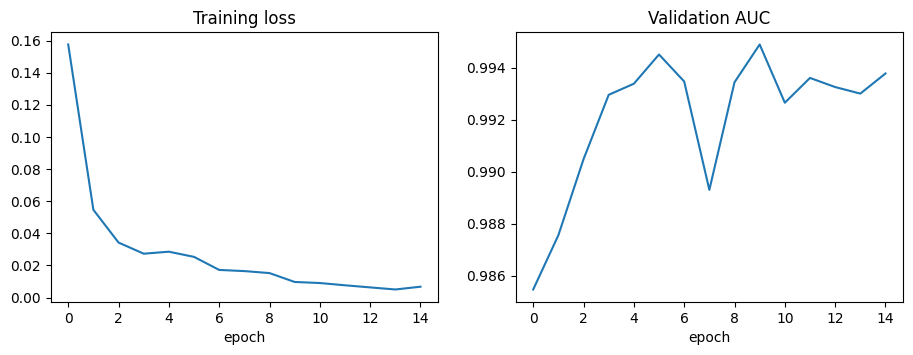

In [5]:
EPOCHS = 15
loss_fn = nn.BCEWithLogitsLoss()
opt = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=1e-4)
sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=0.5, patience=2)
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

@torch.no_grad()
def predict_probs(loader):
    model.eval(); P, Y = [], []
    for x, y in loader:
        with torch.autocast(device_type=device, enabled=use_amp):
            logits = model(x.to(device))
        P += torch.sigmoid(logits.float()).cpu().tolist(); Y += y.tolist()
    return np.array(P), np.array(Y)

hist = {"loss": [], "val_auc": []}
best_auc, best_state = 0.0, None
for epoch in range(1, EPOCHS + 1):
    model.train(); run = 0.0
    for x, y in train_dl:
        x, y = x.to(device), y.float().to(device)
        opt.zero_grad()
        with torch.autocast(device_type=device, enabled=use_amp):
            loss = loss_fn(model(x), y)
        scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        run += loss.item() * len(x)
    p, t = predict_probs(val_dl)
    auc = roc_auc_score(t, p)
    sched.step(auc)
    hist["loss"].append(run / len(train_ds)); hist["val_auc"].append(auc)
    if auc > best_auc:
        best_auc, best_state = auc, copy.deepcopy(model.state_dict())
    print(f"Epoch {epoch:2d}/{EPOCHS}  loss {hist['loss'][-1]:.4f}  val AUC {auc:.4f}  lr {opt.param_groups[0]['lr']:.1e}")

model.load_state_dict(best_state)
torch.save(best_state, "chestscan_densenet121.pt")
print(f"\nBest validation AUC: {best_auc:.4f}  (weights saved)")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(hist["loss"]); ax[0].set_title("Training loss"); ax[0].set_xlabel("epoch")
ax[1].plot(hist["val_auc"]); ax[1].set_title("Validation AUC"); ax[1].set_xlabel("epoch")
plt.show()

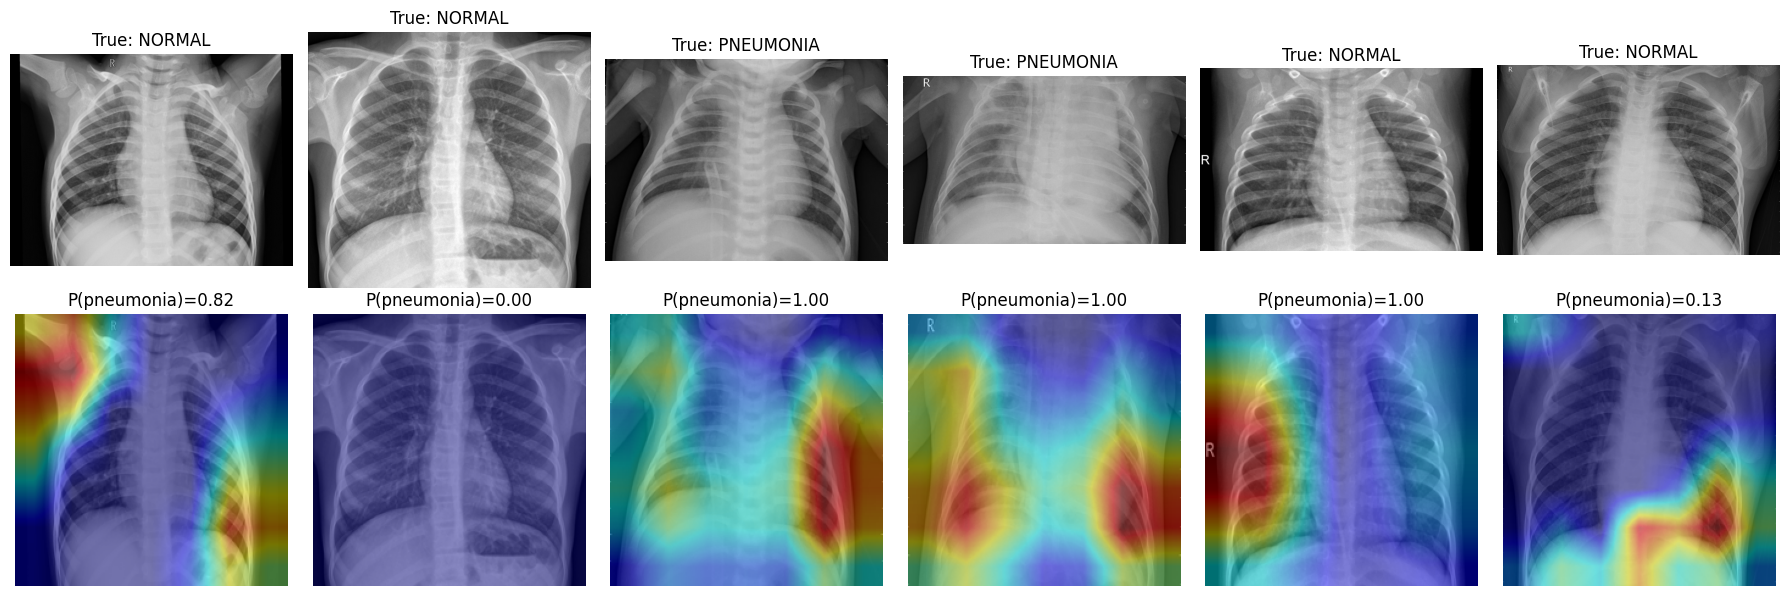

In [6]:
def grad_cam(img_tensor):
    """img_tensor: normalized (3,224,224). Returns (heatmap in [0,1], pneumonia probability)."""
    model.eval(); model.zero_grad()
    x = img_tensor.unsqueeze(0).to(device).requires_grad_(True)
    logit = model(x, capture=True)
    logit.sum().backward()
    acts, grads = model.act.detach(), model.act.grad.detach()          # (1, 1024, 7, 7)
    weights = grads.mean(dim=(2, 3), keepdim=True)
    cam = F.relu((weights * acts).sum(1)).squeeze().cpu().numpy()
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return cam, torch.sigmoid(logit).item()

def overlay(pil_img, cam, alpha=0.45):
    base = np.array(pil_img.convert("RGB").resize((224, 224)))
    heat = cv2.applyColorMap(np.uint8(255 * cv2.resize(cam, (224, 224))), cv2.COLORMAP_JET)
    heat = cv2.cvtColor(heat, cv2.COLOR_BGR2RGB)
    return np.uint8((1 - alpha) * base + alpha * heat)

# Demo on 6 random test images
picks = random.sample(range(len(test_base)), 6)
fig, ax = plt.subplots(2, 6, figsize=(18, 6))
for j, i in enumerate(picks):
    path_i, y = test_base.samples[i]
    pil = Image.open(path_i)
    cam, prob = grad_cam(eval_tf(pil.convert("RGB")))
    ax[0, j].imshow(pil.convert("L"), cmap="gray"); ax[0, j].set_title(f"True: {test_base.classes[y]}"); ax[0, j].axis("off")
    ax[1, j].imshow(overlay(pil, cam)); ax[1, j].set_title(f"P(pneumonia)={prob:.2f}"); ax[1, j].axis("off")
plt.tight_layout(); plt.show()

Test ROC-AUC: 0.9613

--- Test @ default (threshold 0.50) ---
Confusion matrix  [[TN=144 FP=90]  [FN=5 TP=385]]
Sensitivity 98.7%  |  Specificity 61.5%  |  Accuracy 84.8%
Sensitivity target (>90%): ✅ met

--- Test @ high-sensitivity (threshold 0.92) ---
Confusion matrix  [[TN=184 FP=50]  [FN=10 TP=380]]
Sensitivity 97.4%  |  Specificity 78.6%  |  Accuracy 90.4%
Sensitivity target (>90%): ✅ met


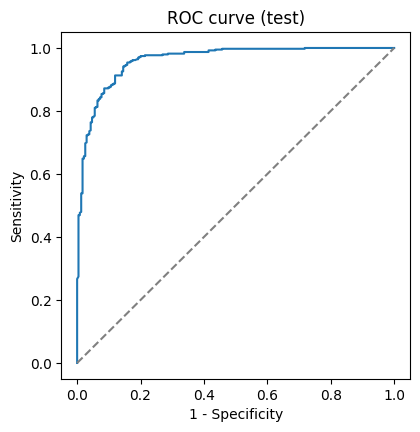

In [7]:
def clinical_report(probs, labels, thr, title):
    pred = (probs >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(labels, pred).ravel()
    sens, spec = tp / (tp + fn), tn / (tn + fp)
    print(f"--- {title} (threshold {thr:.2f}) ---")
    print(f"Confusion matrix  [[TN={tn} FP={fp}]  [FN={fn} TP={tp}]]")
    print(f"Sensitivity {sens:.1%}  |  Specificity {spec:.1%}  |  Accuracy {(tp+tn)/len(labels):.1%}")
    print("Sensitivity target (>90%):", "✅ met" if sens > 0.90 else "❌ not met")
    return sens, spec

pv, yv = predict_probs(val_dl)
pt, yt = predict_probs(test_dl)
print(f"Test ROC-AUC: {roc_auc_score(yt, pt):.4f}\n")

# threshold from validation set: the highest cut-off that still gives >= 95% sensitivity
fpr, tpr, thr = roc_curve(yv, pv)
THR_CLINICAL = float(thr[np.argmax(tpr >= 0.95)])
clinical_report(pt, yt, 0.50, "Test @ default")
print()
clinical_report(pt, yt, THR_CLINICAL, "Test @ high-sensitivity")

fpr_t, tpr_t, _ = roc_curve(yt, pt)
plt.figure(figsize=(4.5, 4.5)); plt.plot(fpr_t, tpr_t); plt.plot([0, 1], [0, 1], "--", c="gray")
plt.xlabel("1 - Specificity"); plt.ylabel("Sensitivity"); plt.title("ROC curve (test)"); plt.show()

In [8]:
UNCERTAINTY_THRESHOLD = 0.10      # tune on validation data

def mc_dropout_predict(img_tensor, n_passes=20):
    model.eval()
    for m in model.modules():                         # re-enable ONLY the dropout layers
        if isinstance(m, nn.Dropout):
            m.train()
    x = img_tensor.unsqueeze(0).repeat(n_passes, 1, 1, 1).to(device)   # 20 stochastic passes in one batch
    with torch.no_grad(), torch.autocast(device_type=device, enabled=use_amp):
        probs = torch.sigmoid(model(x).float()).cpu().numpy()
    model.eval()
    return float(probs.mean()), float(probs.std())

# Uncertainty on the whole test set
means, stds = [], []
for i in range(len(test_base)):
    m, s = mc_dropout_predict(test_ds[i][0]); means.append(m); stds.append(s)
means, stds = np.array(means), np.array(stds)

flag = stds > UNCERTAINTY_THRESHOLD
wrong = ((means >= 0.5).astype(int) != yt)
print(f"Flagged for review: {flag.sum()} of {len(flag)} images ({flag.mean():.1%})")
print(f"Error rate on flagged images  : {wrong[flag].mean():.1%}" if flag.any() else "No images flagged")
print(f"Error rate on unflagged images: {wrong[~flag].mean():.1%}")

Flagged for review: 0 of 624 images (0.0%)
No images flagged
Error rate on unflagged images: 15.2%


In [ ]:
from google.colab import files

uploaded = files.upload()
for name in uploaded:
    pil = Image.open(name).convert("RGB")
    t = eval_tf(pil)
    mean, std = mc_dropout_predict(t)
    cam, _ = grad_cam(t)

    label = "PNEUMONIA" if mean >= THR_CLINICAL else "NORMAL"
    print(f"\n{name}\n  Prediction : {label}   (P(pneumonia) = {mean:.1%}, uncertainty σ = {std:.3f})")
    if std > UNCERTAINTY_THRESHOLD:
        print("  ⚠️  HIGH UNCERTAINTY — flag for radiologist review")
    print("  Educational project only — not a medical diagnosis.")

    fig, ax = plt.subplots(1, 2, figsize=(9, 4.5))
    ax[0].imshow(pil.convert("L"), cmap="gray"); ax[0].set_title("X-ray"); ax[0].axis("off")
    ax[1].imshow(overlay(pil, cam)); ax[1].set_title("Grad-CAM"); ax[1].axis("off")
    plt.show()